# Fase 5 — ¿Qué puede identificar la FC sola? Un índice adimensional de criticalidad

**Datos:** Domhof et al. (EBRAINS), 200 sujetos del HCP, atlas Schaefer de 100 regiones, FC de 4 sesiones en 2 días (ICA-FIX, sin filtro de banda, sin GSR). La FC de grupo es casi idéntica entre mitades de sesiones ($r=0.997$), y la de cada sujeto es individual (consigo mismo $r=0.74$, con otro sujeto $0.53$). El análisis está en `src/fc_only.py`.

## Teoría
Para el modelo de Stuart–Landau linealizado con acoplamiento difusivo y SC simétrica:
1. **Invariancia temporal.** Si $\Sigma$ resuelve $A\Sigma+\Sigma A^\top+\beta^2I=0$, entonces $\Sigma/c$ resuelve la ecuación con $cA$. La FC a retardo cero no cambia al reescalar el tiempo, así que **$\delta$ en s$^{-1}$ no es identificable** solo con FC. Verificación numérica: $|\Delta\mathrm{FC}|<10^{-14}$ mientras $\delta$ se triplica.
2. **La frecuencia desaparece.** Una $\omega$ homogénea se elimina exactamente al pasar a un marco rotatorio ($4\times10^{-15}$). Con $\omega_j$ heterogéneas en la banda del BOLD el efecto es de $\sim0.01$.
3. Por lo tanto $\mathrm{FC}\approx\mathrm{corr}\big[(\mathrm{diag}\,\theta + L)^{-1}\big]$ con $\theta_j=|a_j|/G$. **Solo se identifican los cocientes $\theta_j$.**
4. **Índice adimensional:** $\kappa=\mu_{\min}/\overline{\mu}$, donde $\mu_k$ son los eigenvalores de $\mathrm{diag}\,\theta+L$, es decir, las tasas de relajación en unidades de $G$. $\kappa\to0$ significa que el modo más lento se separa de los demás (*critical slowing* relativo). Con $\theta$ homogéneo y la SC normalizada a fuerza media 1, $\kappa=\theta/(\theta+1)$.

ajuste por sesión (mediana de r(FC)):
  SC propia GSR=no: r=0.188  kappa=0.0181
  SC propia GSR=sí: r=0.291  kappa=0.0768
  SC grupo  GSR=no: r=0.187  kappa=0.0186
  SC grupo  GSR=sí: r=0.294  kappa=0.0673

reproducibilidad          ICC4   ICCdía  r(FC media)  ICC sin FC media
  SC propia GSR=no   0.628  0.654   -0.994       0.322
  SC propia GSR=sí   0.648  0.767   -0.245       0.645
  SC grupo  GSR=no   0.628  0.654   -0.995       0.299
  SC grupo  GSR=sí   0.470  0.596   -0.418       0.407


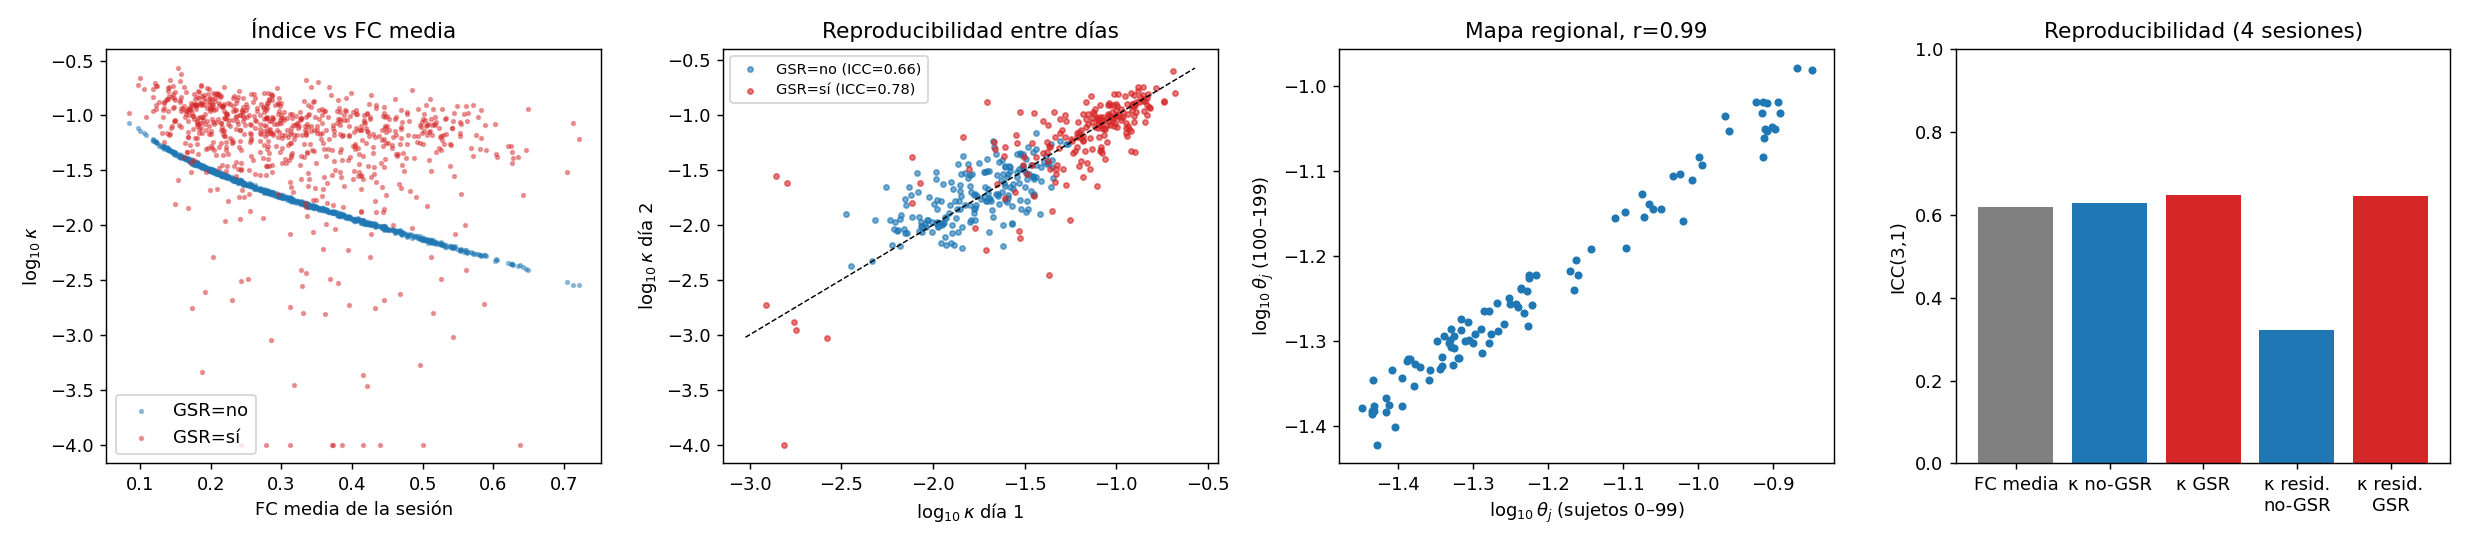

In [1]:
import numpy as np
from pathlib import Path
from IPython.display import Image, display
ROOT = Path.cwd().parent if Path.cwd().name == 'notebooks' else Path.cwd()
r = np.load(ROOT/'results'/'fase5_fc_only.npz'); c = np.load(ROOT/'results'/'fase5_control_sc.npz')
print('ajuste por sesión (mediana de r(FC)):')
for k in ['propia_0','propia_1','grupo_0','grupo_1']:
    print(f"  SC {k.split('_')[0]:6s} GSR={'sí' if k.endswith('1') else 'no'}: r={np.median(r['RR_'+k]):.3f}  kappa={np.median(r['KA_'+k]):.4f}")
print('\nreproducibilidad          ICC4   ICCdía  r(FC media)  ICC sin FC media')
for key, s in zip(r['keys'], r['summary']):
    sc, g = key.split('|'); print(f"  SC {sc:6s} GSR={'sí' if g=='1' else 'no'}   {s[0]:.3f}  {s[1]:.3f}   {s[2]:+.3f}       {s[3]:.3f}")
display(Image(str(ROOT/'figures'/'fase5_indice_relativo.png')))

## Resultados

**1. Sin GSR, el índice es solo la FC media.** $\log\kappa$ correlaciona $-0.99$ con la FC media de la sesión. Esa FC media varía de 0.08 a 0.72 entre sesiones y la domina la señal global (respiración, nivel de vigilia, movimiento). Un índice así no mide nada nuevo.

**2. Con GSR aparece un rasgo individual modesto pero real.** Hay que usar la **SC de grupo**, por el control del punto 3:

| | ICC (4 sesiones) | ICC (día 1 vs 2) | ICC sin la FC media |
|---|---|---|---|
| FC media | 0.62 | 0.65 | — |
| $\log\kappa$, SC de grupo, GSR | **0.47** | **0.60** | **0.41** |

$\kappa$ correlaciona solo $-0.42$ con la FC media, así que lleva información distinta del nivel global.

**3. Control: usar la SC propia infla la reproducibilidad.** Con la SC de cada sujeto la ICC sube a 0.65, pero con la SC de **otro** sujeto (fija en las 4 sesiones) sigue en 0.60. La ganancia viene de la anatomía y no de la FC: la SC es la misma en todas las sesiones, y $\kappa$ correlaciona $-0.61$ con $\lambda_2$ de la SC propia. Además, la SC propia no mejora el ajuste (diferencia en $r$ de $-0.002$).

**4. El modelo ajusta mal la FC individual.** Con GSR, $r\approx0.29$ por sesión; a nivel de grupo, $0.38$ frente a un techo de 0.996. El índice sale de un modelo de un parámetro con SC cruda, así que hay que leerlo como un **resumen espectral reproducible**, no como una medida mecanística de criticalidad.

**5. Un mapa reproducible no implica un mapa con significado.** Los $\theta_j$ regionales son casi idénticos entre las dos mitades de sujetos ($r=0.99$), pero predicen la otra mitad apenas mejor que barajados (0.393 frente a 0.380). Como las FC de grupo de ambas mitades son prácticamente iguales, cualquier ajuste determinista va a dar el mismo mapa. La reproducibilidad entre grupos no valida parámetros cuando el objetivo es el mismo.

## Implicaciones
- Con FC sola se puede estudiar un **índice relativo** ($\kappa$ con GSR y SC de grupo) con reproducibilidad moderada (ICC entre días de 0.60). Eso es suficiente para comparar grupos grandes, por ejemplo TEA frente a controles en ABIDE con unos 1,000 sujetos, pero no para diagnóstico individual.
- El paso que más mejoraría todo es **un mejor modelo de la FC**: con conectividad efectiva simétrica por grupo o con SC transformada, el $r$ de grupo debería pasar de 0.38 a 0.7–0.9. Con $\kappa$ derivado de un modelo que sí ajusta, la interpretación como cercanía a la bifurcación sería más defendible.
- Para $\delta$ en segundos siguen haciendo falta series de tiempo.